# 01 · Data Exploration

| Dataset | Source | Target |
|---|---|---|
| `diabetes` | BRFSS 2015 diabetes health indicators (Teboul, 2021) | `Diabetes_binary` |
| `cardiovascular` | Cardiovascular disease dataset (Ulianova, 2018) | `cardio` |

All configuration (paths, column types, validity rules) lives in `data_pipeline.py`. Figures are saved to `results/eda/`.

## Environment initialization and pipeline configuration

In [2]:
# Enable inline rendering of matplotlib figures within the Jupyter Notebook interface
%matplotlib inline

import pandas as pd
from IPython.display import display

# Import custom visualization utilities and standardize plotting aesthetics
import eda_plots as ep

# Import constant definitions and utility functions for the data processing pipeline.
# These encompass data ingestion (load_raw), cleaning operations (apply_cleaning), 
# and statistical diagnostics (column_audit, iqr_outlier_summary, etc.).
from data_pipeline import (
    DATASETS,
    apply_cleaning,
    column_audit,
    iqr_outlier_summary,
    load_raw,
    top_correlated_pairs,
    validity_violations,
)

# Remove the default column truncation limit to ensure full visibility 
# when inspecting high-dimensional DataFrames
pd.set_option("display.max_columns", None)

# Apply standardized formatting and visual styles to all subsequent plots via the custom module
ep.set_style()

# Output the list of registered datasets from the pipeline to verify correct configuration
print("Datasets configured:", ", ".join(DATASETS))

Datasets configured: diabetes, cardiovascular


## Load raw data and audit the schema

`load_raw` validates that the file's columns match the configuration exactly (missing *or* unexpected columns raise an error), so a schema change in the source data cannot pass silently.

In [3]:
# Instantiate a dictionary of DataFrames using dictionary comprehension.
# Iterates through the DATASETS configuration mapping to load and validate each file.
raw = {name: load_raw(cfg) for name, cfg in DATASETS.items()}

# Construct a metadata summary matrix for all loaded datasets
overview = pd.DataFrame(
    {
        name: {
            "rows": len(df),
            "columns": df.shape[1],
            # Calculate exact memory footprint, including object-level introspection (deep=True), 
            # and convert bytes to Megabytes for readability.
            "memory (MB)": round(df.memory_usage(deep=True).sum() / 1e6, 1),
            "file": DATASETS[name].file,
        }
        for name, df in raw.items()
    }
).T  # Transpose the DataFrame to orient datasets as rows and metrics as columns

# Render the compiled metadata overview 
display(overview)

# Iterate through the instantiated datasets to perform a structural integrity check
for name, df in raw.items():
    print(f"\n{name.upper()} - column audit (declared type vs observed data)")
    
    # Evaluate and display discrepancies between the empirically observed data types 
    # in the DataFrame and the expected schema defined in the configuration.
    display(column_audit(df, DATASETS[name]))

,rows,columns,memory (MB),file
diabetes,253680,22,44.6,data/raw/diabetes/diabetes.csv
cardiovascular,70000,13,7.3,data/raw/cardiovascular/cardiovascular.csv



DIABETES - column audit (declared type vs observed data)


,declared,dtype,n_unique,n_missing,min,max,integer_valued,note
Diabetes_binary,target,float64,2,0,0.0,1.0,True,
HighBP,binary,float64,2,0,0.0,1.0,True,
HighChol,binary,float64,2,0,0.0,1.0,True,
CholCheck,binary,float64,2,0,0.0,1.0,True,
BMI,numeric,float64,84,0,12.0,98.0,True,
Smoker,binary,float64,2,0,0.0,1.0,True,
Stroke,binary,float64,2,0,0.0,1.0,True,
HeartDiseaseorAttack,binary,float64,2,0,0.0,1.0,True,
PhysActivity,binary,float64,2,0,0.0,1.0,True,
Fruits,binary,float64,2,0,0.0,1.0,True,



CARDIOVASCULAR - column audit (declared type vs observed data)


,declared,dtype,n_unique,n_missing,min,max,integer_valued,note
id,id,int64,70000,0,0,99999,True,
age,numeric,int64,8076,0,10798,23713,True,
gender,binary,int64,2,0,1,2,True,
height,numeric,int64,109,0,55,250,True,
weight,numeric,float64,287,0,10.0,200.0,False,
ap_hi,numeric,int64,153,0,-150,16020,True,
ap_lo,numeric,int64,157,0,-70,11000,True,
cholesterol,ordinal,int64,3,0,1,3,True,
gluc,ordinal,int64,3,0,1,3,True,
smoke,binary,int64,2,0,0,1,True,


**Reading the audit**

- `diabetes`: every column is stored as `float64` although all values are integers → downcast to `int8`/`int16` in `02` (roughly 8× less memory, and the binary/ordinal intent becomes explicit).
- `cardiovascular`: `age` is in **days**; `gender` is coded 1/2 (not 0/1); `cholesterol` and `gluc` take ordered levels 1–3, so they are **ordinal**, not nominal.
- Any text in the `note` column means the configuration and the data disagree and must be resolved.

## Missing values

In [4]:
# Iterate through each loaded dataset to diagnose data completeness and evaluate missingness patterns
for name, df in raw.items():
    # Compute the total count of null/NaN values per feature column
    missing = df.isna().sum()
    
    # Filter out complete features, retaining only columns with at least one missing entry
    missing = missing[missing > 0]
    
    if missing.empty:
        print(f"{name.upper()}: no missing values.")
    else:
        print(f"{name.upper()}:")
        # Construct and display a summary table reporting absolute counts and proportion (%) 
        # of missing values, ordered by degree of missingness in descending order
        display(
            pd.DataFrame({
                "missing": missing, 
                "missing %": (100 * missing / len(df)).round(2)
            })
            .sort_values("missing", ascending=False)
        )

DIABETES: no missing values.
CARDIOVASCULAR: no missing values.


## Descriptive statistics

In [5]:
# Iterate through each loaded dataset to perform parametric and non-parametric statistical profiling
for name, df in raw.items():
    cfg = DATASETS[name]
    numeric = list(cfg.numeric)

    # Generate standard summary statistics, explicitly adding extreme percentiles (1st and 99th) 
    # to inspect heavy tails and potential outliers; transpose so features form rows
    stats = df[numeric].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
    
    # Calculate higher-order distributional moments: asymmetry (skewness) and tail heaviness (kurtosis)
    stats["skew"] = df[numeric].skew()
    stats["kurtosis"] = df[numeric].kurt()
    
    # Measure feature sparsity by computing the proportion of zero-valued observations
    stats["zero share"] = (df[numeric] == 0).mean()
    
    print(f"\n{name.upper()} - numeric features")
    display(stats.round(3))

    # Evaluate balance in dichotomous variables by calculating the relative frequency/prevalence 
    # of the higher binary encoding value (e.g., 1 in a {0, 1} encoding scheme)
    binary_share = df[list(cfg.binary)].apply(lambda s: (s == s.max()).mean())
    
    print(f"{name.upper()} - binary features: share at the higher code")
    display(binary_share.sort_values().round(3).rename("share").to_frame())


DIABETES - numeric features


,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,kurtosis,zero share
BMI,253680.0,28.382,6.609,12.0,18.0,24.0,27.0,31.0,50.0,98.0,2.122,10.997,0.000
MentHlth,253680.0,3.185,7.413,0.0,0.0,0.0,0.0,2.0,30.0,30.0,2.721,6.442,0.693
PhysHlth,253680.0,4.242,8.718,0.0,0.0,0.0,0.0,3.0,30.0,30.0,2.207,3.496,0.631


DIABETES - binary features: share at the higher code


,share
Stroke,0.041
HvyAlcoholConsump,0.056
NoDocbcCost,0.084
HeartDiseaseorAttack,0.094
DiffWalk,0.168
HighChol,0.424
HighBP,0.429
Sex,0.440
Smoker,0.443
Fruits,0.634



CARDIOVASCULAR - numeric features


,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,kurtosis,zero share
age,70000.0,19468.866,2467.252,10798.0,14466.0,17664.0,19703.0,21327.0,23489.0,23713.0,-0.307,-0.823,0.0
height,70000.0,164.359,8.210,55.0,147.0,159.0,165.0,170.0,184.0,250.0,-0.642,7.944,0.0
weight,70000.0,74.206,14.396,10.0,48.0,65.0,72.0,82.0,117.0,200.0,1.012,2.587,0.0
ap_hi,70000.0,128.817,154.011,-150.0,90.0,120.0,120.0,140.0,180.0,16020.0,85.296,7580.075,0.0
ap_lo,70000.0,96.630,188.473,-70.0,60.0,80.0,80.0,90.0,1000.0,11000.0,32.114,1425.915,0.0


CARDIOVASCULAR - binary features: share at the higher code


,share
alco,0.054
smoke,0.088
gender,0.350
active,0.804


## Class balance

DIABETES


,class,count,share %
Diabetes_binary,,,
0.0,No diabetes,218334,86.07
1.0,Diabetes,35346,13.93


Imbalance ratio (majority : minority) = 6.18 : 1


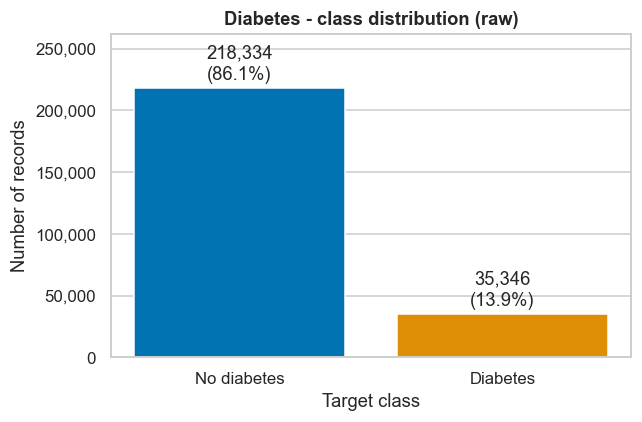

CARDIOVASCULAR


,class,count,share %
cardio,,,
0,No CVD,35021,50.03
1,CVD,34979,49.97


Imbalance ratio (majority : minority) = 1.00 : 1


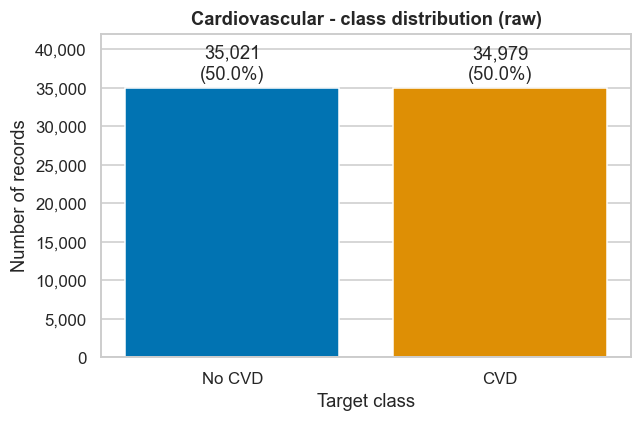

In [6]:
# Iterate through each loaded dataset to evaluate target variable balance and distribution
for name, df in raw.items():
    cfg = DATASETS[name]
    
    # Compute absolute frequency counts for each target category, ordered by class index
    counts = df[cfg.target].value_counts().sort_index()
    
    # Construct a structured summary DataFrame mapping encoded target keys (k) 
    # to their corresponding human-readable labels alongside relative percentages
    summary = pd.DataFrame(
        {
            "class": [cfg.class_labels[int(k)] for k in counts.index],
            "count": counts.values,
            "share %": (100 * counts / len(df)).round(2).values,
        },
        index=counts.index,
    )
    
    print(name.upper())
    display(summary)
    
    # Quantify the degree of class imbalance by computing the ratio of majority-to-minority frequency
    print(f"Imbalance ratio (majority : minority) = {counts.max() / counts.min():.2f} : 1")
    
    # Render and export a graphical plot of the unadjusted class distribution to a PNG file
    ep.plot_class_distribution(
        df[cfg.target], 
        cfg.class_labels,
        f"{name.capitalize()} - class distribution (raw)", 
        f"{name}_class_distribution.png",
    )

## Duplicates

Three different counts are easy to confuse, so all are reported:

- **Redundant copies** (`keep="first"`): rows that would be *removed* by de-duplication.
- **Rows in a duplicate group** (`keep=False`): every row that shares its values with at least one other row (original + copies).
- **Conflicting-label profiles**: rows whose *feature vector* also appears with the opposite label. These are irreducible noise and cap achievable accuracy.

Duplicates are detected on the **modelling columns** (features + target), ignoring identifiers.

In [7]:
# Initialize storage for dataset-level deduplication metrics
dup_stats = {}

# Iterate through each dataset to analyze duplicate records and label inconsistencies
for name, df in raw.items():
    cfg = DATASETS[name]
    target = cfg.target
    model_cols = list(cfg.modeling_columns)

    # Flag redundant copies beyond the first occurrence within the feature/target subset (candidates for removal)
    redundant = df.duplicated(subset=model_cols, keep="first")
    
    # Flag all records participating in any duplicate group (keep=False retains all instances for group evaluation)
    in_group = df.duplicated(subset=model_cols, keep=False)
    
    # Detect label ambiguity: identify instances where identical feature vectors are mapped to multiple distinct target classes
    conflicting = (
        df.groupby(list(cfg.feature_columns), sort=False)[target].transform("nunique") > 1
    )

    # Compile dataset-wide diagnostic metrics into a summary table
    summary = pd.Series(
        {
            "rows": len(df),
            "duplicates when id columns are included (original check)": int(df.duplicated().sum()),
            "redundant copies (keep first) - remove in 02": int(redundant.sum()),
            "rows in any duplicate group (keep=False)": int(in_group.sum()),
            "duplicate groups": df.loc[in_group].groupby(model_cols, sort=False).ngroups,
            "rows whose feature vector has conflicting labels": int(conflicting.sum()),
        }
    )
    print(name.upper())
    display(summary.to_frame("count"))

    # Analyze how duplication and removal affect each target class individually
    by_class = pd.DataFrame(
        {
            "rows": df[target].value_counts().sort_index(),
            "rows in duplicate groups": df.loc[in_group, target].value_counts().sort_index(),
            "remove by de-duplication": df.loc[redundant, target].value_counts().sort_index(),
        }
    ).fillna(0).astype(int)
    
    # Compute the percentage of each target class contained within duplicate clusters
    by_class["% of class in duplicate groups"] = (
        100 * by_class["rows in duplicate groups"] / by_class["rows"]
    ).round(2)
    
    # Map encoded numeric indices to human-readable class labels
    by_class.index = [cfg.class_labels[int(k)] for k in by_class.index]
    display(by_class)

    # Calculate target class prevalence (mean of binary target) prior to and post deduplication
    prev_before, prev_after = df[target].mean(), df.loc[~redundant, target].mean()
    print(f"Positive-class prevalence: {prev_before:.2%} -> {prev_after:.2%} after de-duplication\n")

    # Save summary statistics for downstream pipeline reference
    dup_stats[name] = {
        "redundant": int(redundant.sum()),
        "pct": 100 * redundant.mean(),
        "prev_before": prev_before,
        "prev_after": prev_after,
        "conflicting_rows": int(conflicting.sum()),
    }

DIABETES


,count
rows,253680
duplicates when id columns are included (original check),24206
redundant copies (keep first) - remove in 02,24206
rows in any duplicate group (keep=False),35575
duplicate groups,11369
rows whose feature vector has conflicting labels,5218


,rows,rows in duplicate groups,remove by de-duplication,% of class in duplicate groups
No diabetes,218334,35096,23957,16.07
Diabetes,35346,479,249,1.36


Positive-class prevalence: 13.93% -> 15.29% after de-duplication

CARDIOVASCULAR


,count
rows,70000
duplicates when id columns are included (original check),0
redundant copies (keep first) - remove in 02,24
rows in any duplicate group (keep=False),48
duplicate groups,24
rows whose feature vector has conflicting labels,34


,rows,rows in duplicate groups,remove by de-duplication,% of class in duplicate groups
No CVD,35021,34,17,0.10
CVD,34979,14,7,0.04


Positive-class prevalence: 49.97% -> 49.98% after de-duplication



**Decision:** exact duplicates (on the modelling columns) will be **removed**, keeping the first occurrence.

*Why:* identical rows must not land in both the training pool and the test set. *Cost:* removal is not class-neutral, it disproportionately removes majority-class profiles and therefore raises the positive-class prevalence (see above).

## Anomalies and outliers

Two lenses: (a) the domain **validity rules** from the configuration, (b) a generic **IQR screen**. The IQR screen flags many legitimate values in skewed or zero-inflated columns, so it informs but never drives removal.


DIABETES
No validity rules configured: values are retained as they are.
IQR outlier screen (1.5 x IQR fences):


,min,q1,q3,max,lower_fence,upper_fence,n_below,n_above,% outside fences
BMI,12.0,24.0,31.0,98.0,13.5,41.5,27.0,9820.0,3.88
MentHlth,0.0,0.0,2.0,30.0,-3.0,5.0,0.0,36208.0,14.27
PhysHlth,0.0,0.0,3.0,30.0,-4.5,7.5,0.0,40949.0,16.14



CARDIOVASCULAR


,rows violating,% of rows
"ap_hi outside [60, 250]",228.0,0.33
"ap_lo outside [40, 160]",1025.0,1.46
"height outside [100, 220]",30.0,0.04
"weight outside [30, 200]",7.0,0.01
ap_hi <= ap_lo,1236.0,1.77
ANY rule (rows removed),1364.0,1.95


IQR outlier screen (1.5 x IQR fences):


,min,q1,q3,max,lower_fence,upper_fence,n_below,n_above,% outside fences
age,10798.0,17664.0,21327.0,23713.0,12169.5,26821.5,4.0,0.0,0.01
height,55.0,159.0,170.0,250.0,142.5,186.5,250.0,269.0,0.74
weight,10.0,65.0,82.0,200.0,39.5,107.5,52.0,1767.0,2.60
ap_hi,-150.0,120.0,140.0,16020.0,90.0,170.0,321.0,1114.0,2.05
ap_lo,-70.0,80.0,90.0,11000.0,65.0,105.0,2932.0,1700.0,6.62


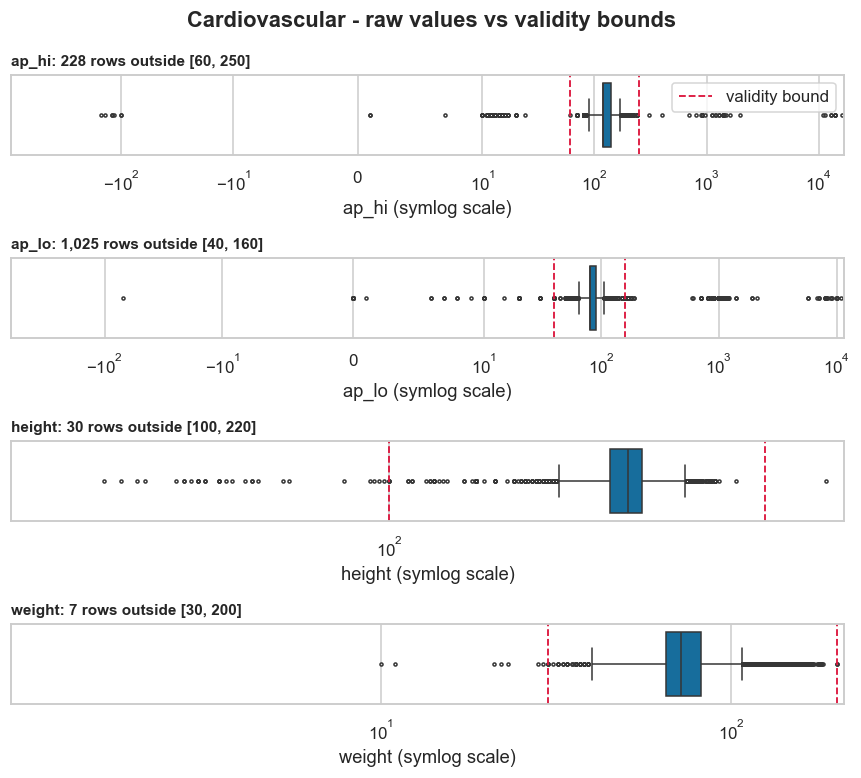

In [8]:
# Iterate through each loaded dataset to perform domain validity verification and anomaly screening
for name, df in raw.items():
    cfg = DATASETS[name]
    print(f"\n{name.upper()}")

    # Generate a boolean DataFrame where each column represents a configured validity rule and True indicates a violation
    violations = validity_violations(df, cfg)
    if violations.shape[1] == 0:
        print("No validity rules configured: values are retained as they are.")
    else:
        # Compile individual rule violation metrics (absolute count and relative percentage)
        table = pd.DataFrame(
            {"rows violating": violations.sum(), "% of rows": (100 * violations.mean()).round(2)}
        )
        # Append an aggregate row capturing records violating at least one rule (union across rules along axis=1)
        table.loc["ANY rule (rows removed)"] = [
            int(violations.any(axis=1).sum()), round(100 * violations.any(axis=1).mean(), 2),
        ]
        display(table)

    print("IQR outlier screen (1.5 x IQR fences):")
    # Screen continuous variables for statistical anomalies using non-parametric Interquartile Range (IQR) bounds
    display(iqr_outlier_summary(df, cfg.numeric))

    # Render and save boxplots overlaying empirical feature distributions against domain range constraints
    if cfg.range_rules:
        ep.plot_boxplots_with_bounds(
            df, cfg.range_rules,
            f"{name.capitalize()} - raw values vs validity bounds", f"{name}_raw_boxplots.png",
        )

**Decisions**

- `cardiovascular`: physiologically implausible values will be removed using the ranges reported in the EXHEART preprocessing pipeline: `ap_hi` ∈ [60, 250] mmHg, `ap_lo` ∈ [40, 160] mmHg, `height` ∈ [100, 220] cm, and `weight` ∈ [30, 200] kg (Biswas & Laila, 2026). Records with `ap_hi <= ap_lo` will additionally be removed as an internal physiological-consistency check.
- `diabetes`: no rows will be removed for extreme values. Raw BMI spans 12–98, which is retained as in the original pipeline.

## Distributions by class

Density-normalised per class so a class imbalance does not distort the comparison; the x-axis is clipped to the 0.5–99.5th percentile and each panel says how many values are outside the view.

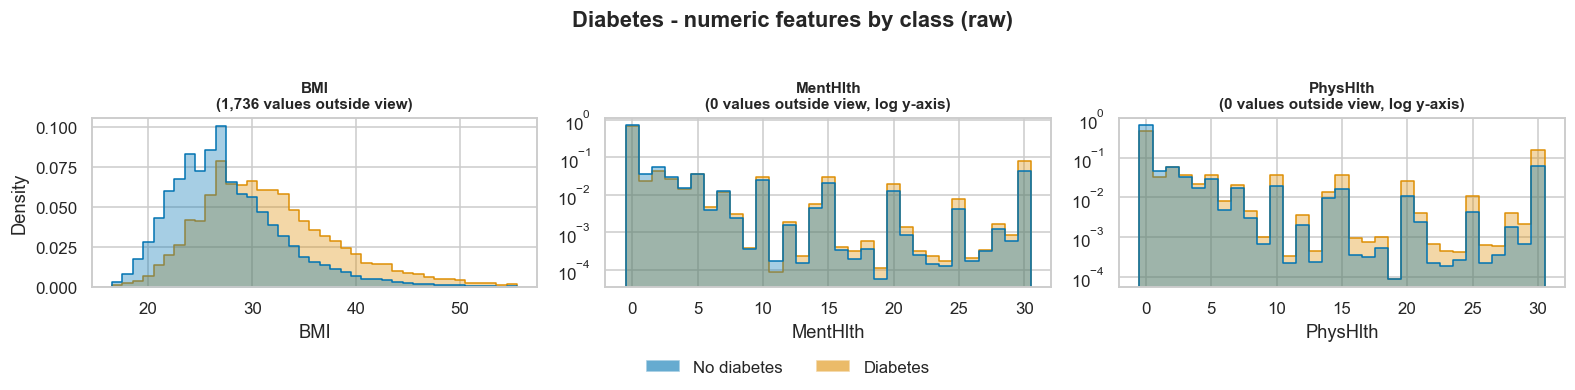

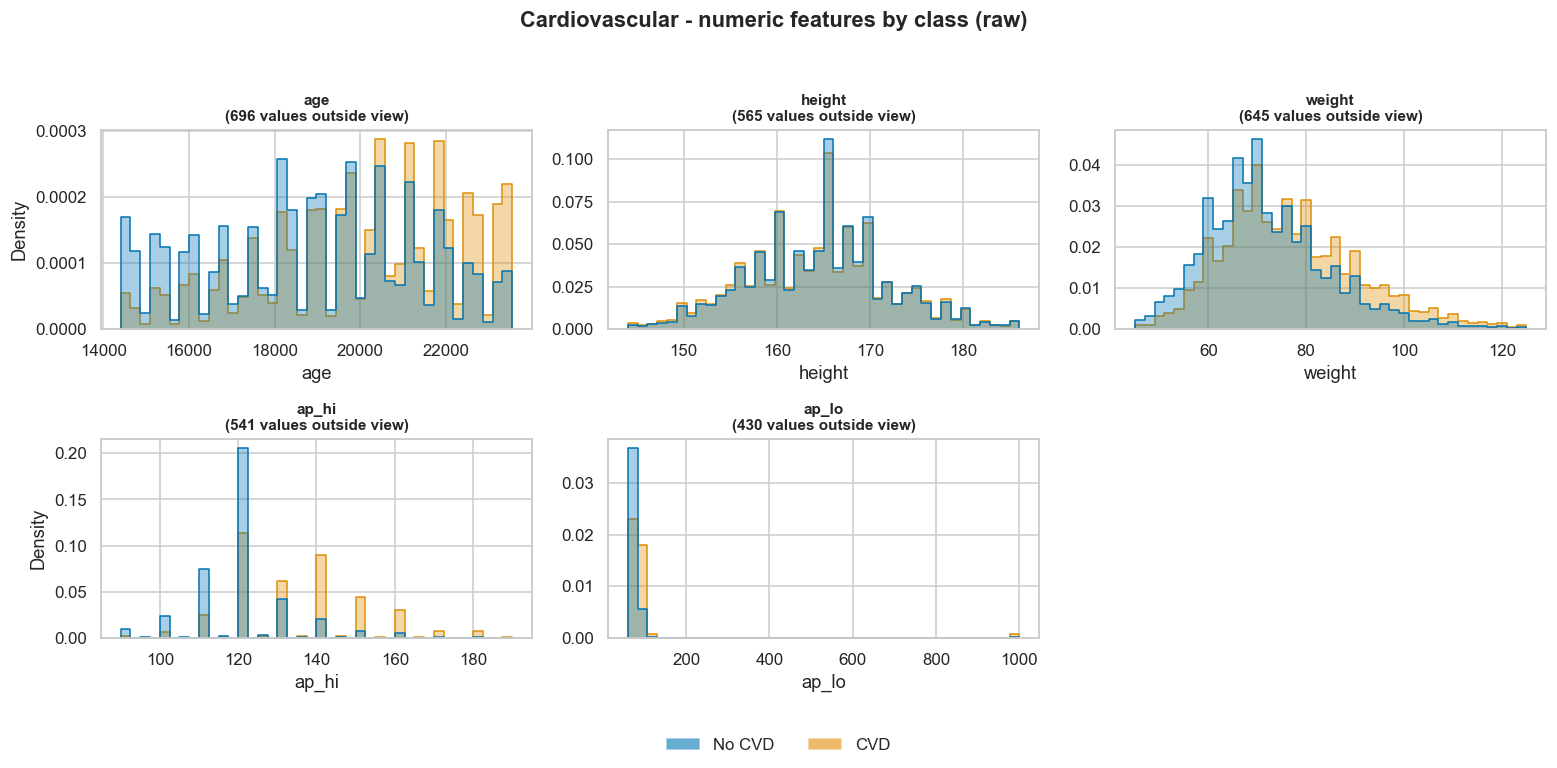

In [9]:
# Iterate through each dataset to visualize feature behavior conditioned on target class membership
for name, df in raw.items():
    cfg = DATASETS[name]
    
    # Render and save class-stratified plots (e.g., overlaid KDE curves or side-by-side boxplots) 
    # for all numeric features to assess univariate class-separability
    ep.plot_numeric_by_class(
        df, 
        cfg.numeric,       # List of continuous feature names to profile
        cfg.target,        # Name of the target variable column
        cfg.class_labels,  # Dictionary or list mapping class codes to descriptive names
        f"{name.capitalize()} - numeric features by class (raw)", 
        f"{name}_numeric_by_class.png",  # Destination filename for exported plot
    )

## 8 · Feature–target relationships

Spearman correlation is used because it is rank-based (robust to the outliers found above) and valid for binary and ordinal features. The second figure shows the positive-class rate at each level of the ordinal features and the four strongest binary ones.

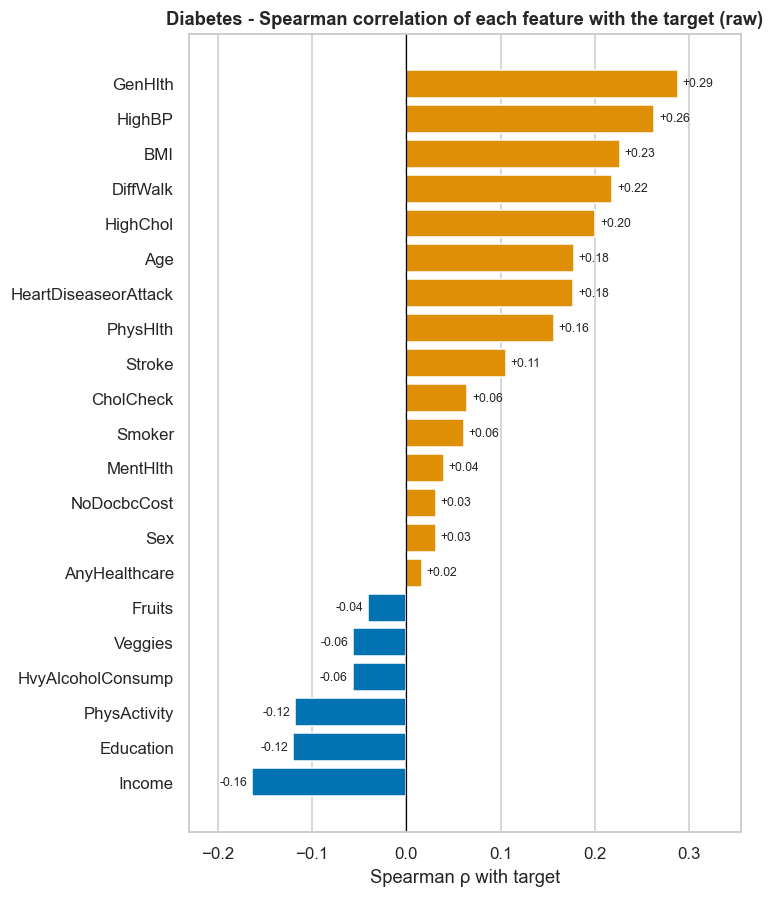

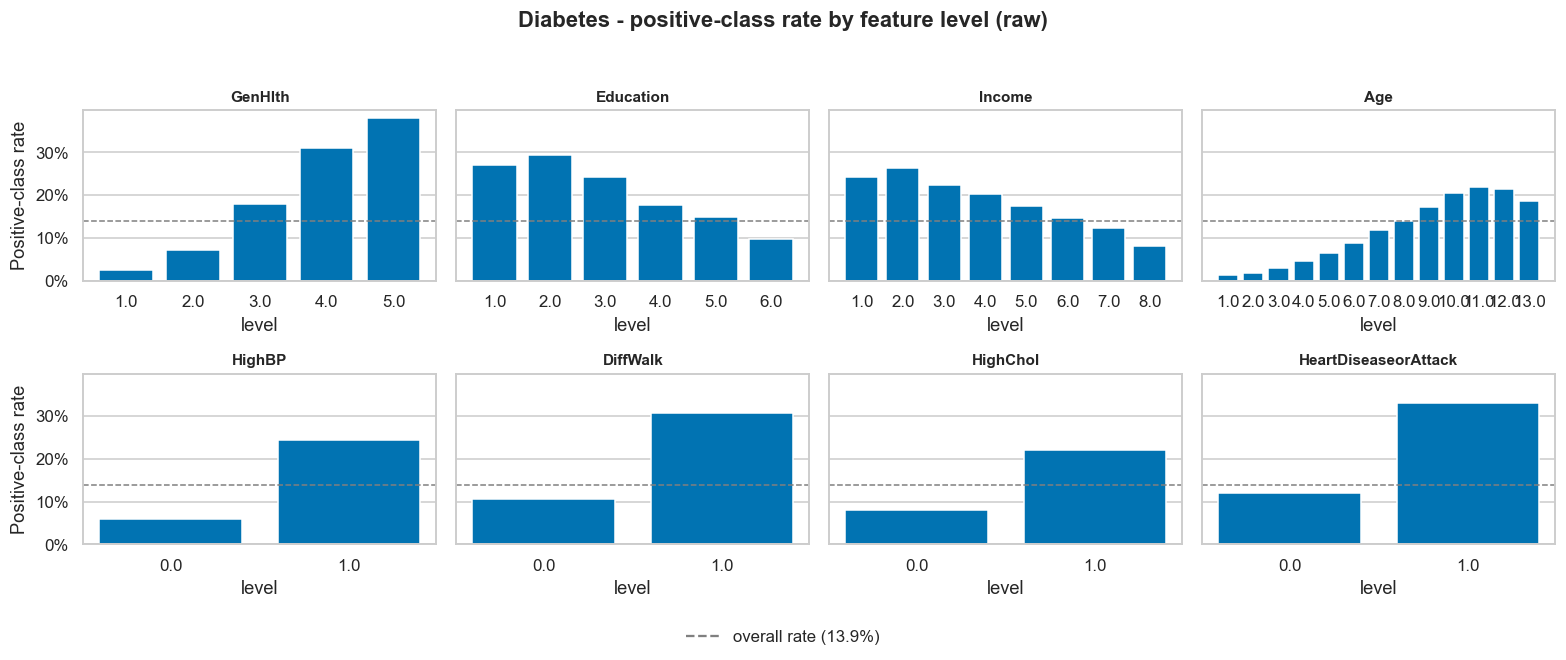

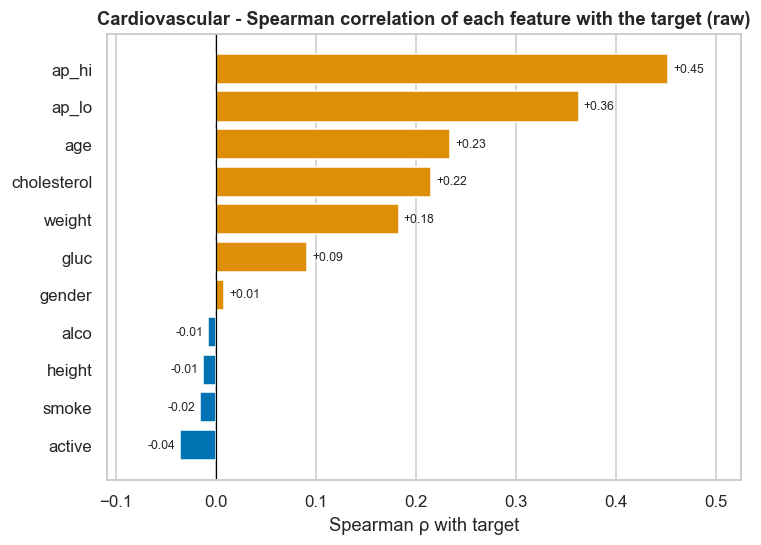

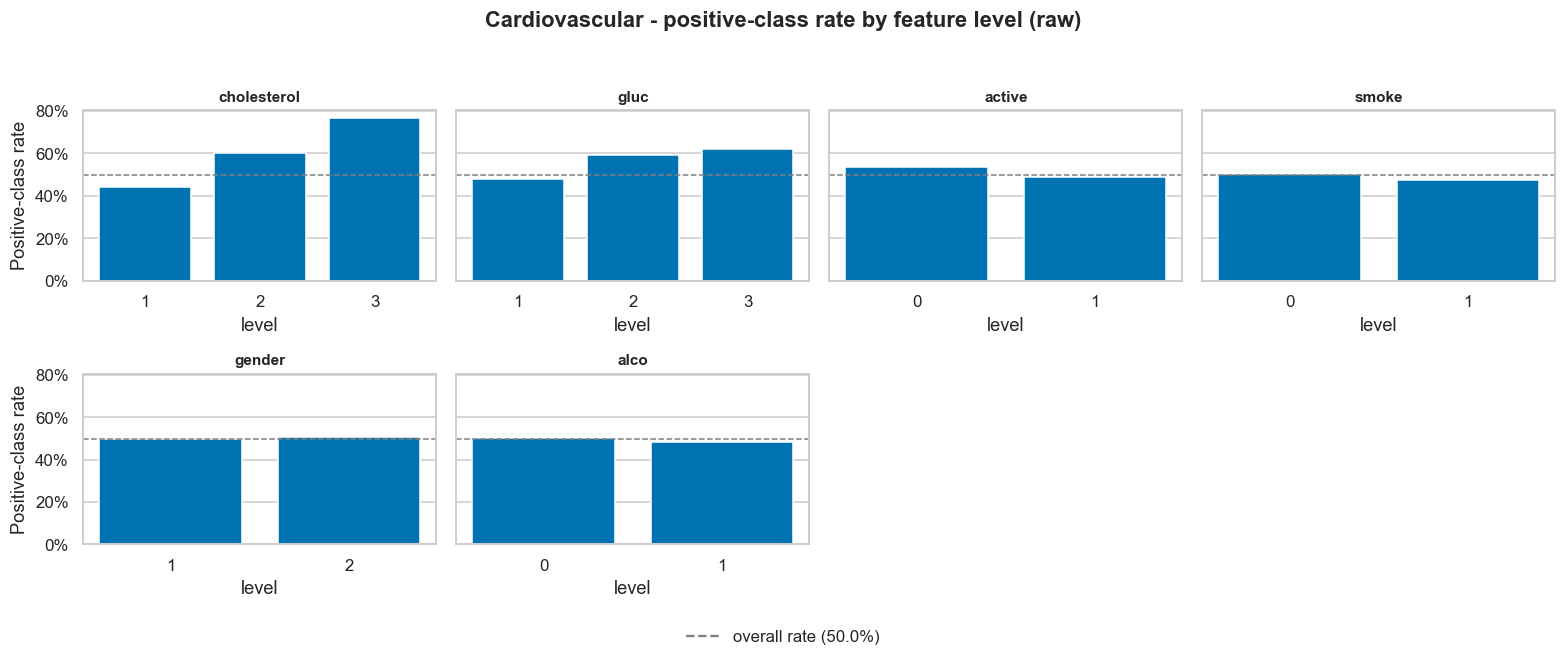

In [10]:
# Initialize storage for feature-target correlation series across datasets
associations = {}

# Iterate through datasets to evaluate feature relationship strength with the response variable
for name, df in raw.items():
    cfg = DATASETS[name]
    
    # Compute non-parametric Spearman rank correlation to measure monotonic association 
    # between each predictor and the target variable, sorting values from strongest negative to strongest positive
    assoc = df[list(cfg.feature_columns)].corrwith(df[cfg.target], method="spearman").sort_values()
    associations[name] = assoc

    # Render and export a plot summarizing feature-target Spearman correlation coefficients
    ep.plot_target_association(
        assoc, 
        f"{name.capitalize()} - Spearman correlation of each feature with the target (raw)",
        f"{name}_target_association.png",
    )

    # Identify the top 4 binary features exhibiting the strongest absolute correlation magnitude
    top_binary = assoc[list(cfg.binary)].abs().nlargest(4).index.tolist()
    
    # Render conditional positive-class rates across levels of ordinal and high-association binary features;
    # supplies the global mean target rate ('overall') as a baseline reference line
    ep.plot_target_rate_by_level(
        df, 
        [*cfg.ordinal, *top_binary], 
        cfg.target,
        f"{name.capitalize()} - positive-class rate by feature level (raw)",
        f"{name}_target_rate_by_level.png", 
        overall=df[cfg.target].mean(),
    )

## Cleaning preview


DIABETES


,rows_before,rows_removed,rows_after,pct_removed,target_prevalence
step,,,,,
raw,253680,0,253680,0.00,0.1393
1. drop exact duplicates,253680,24206,229474,9.54,0.1529
2. apply validity rules,229474,0,229474,0.00,0.1529


Memory: 44.6 MB -> 7.6 MB


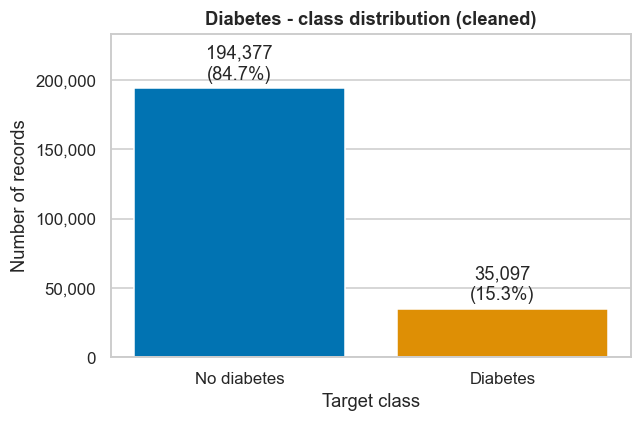


CARDIOVASCULAR


,rows_before,rows_removed,rows_after,pct_removed,target_prevalence
step,,,,,
raw,70000,0,70000,0.00,0.4997
1. drop exact duplicates,70000,24,69976,0.03,0.4998
2. apply validity rules,69976,1364,68612,1.95,0.4948


,rows violating (after de-duplication)
"ap_hi outside [60, 250]",228
"ap_lo outside [40, 160]",1025
"height outside [100, 220]",30
"weight outside [30, 200]",7
ap_hi <= ap_lo,1236


Memory: 7.3 MB -> 3.1 MB


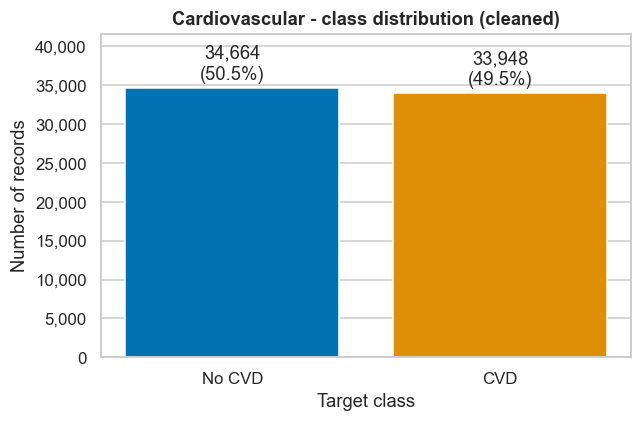

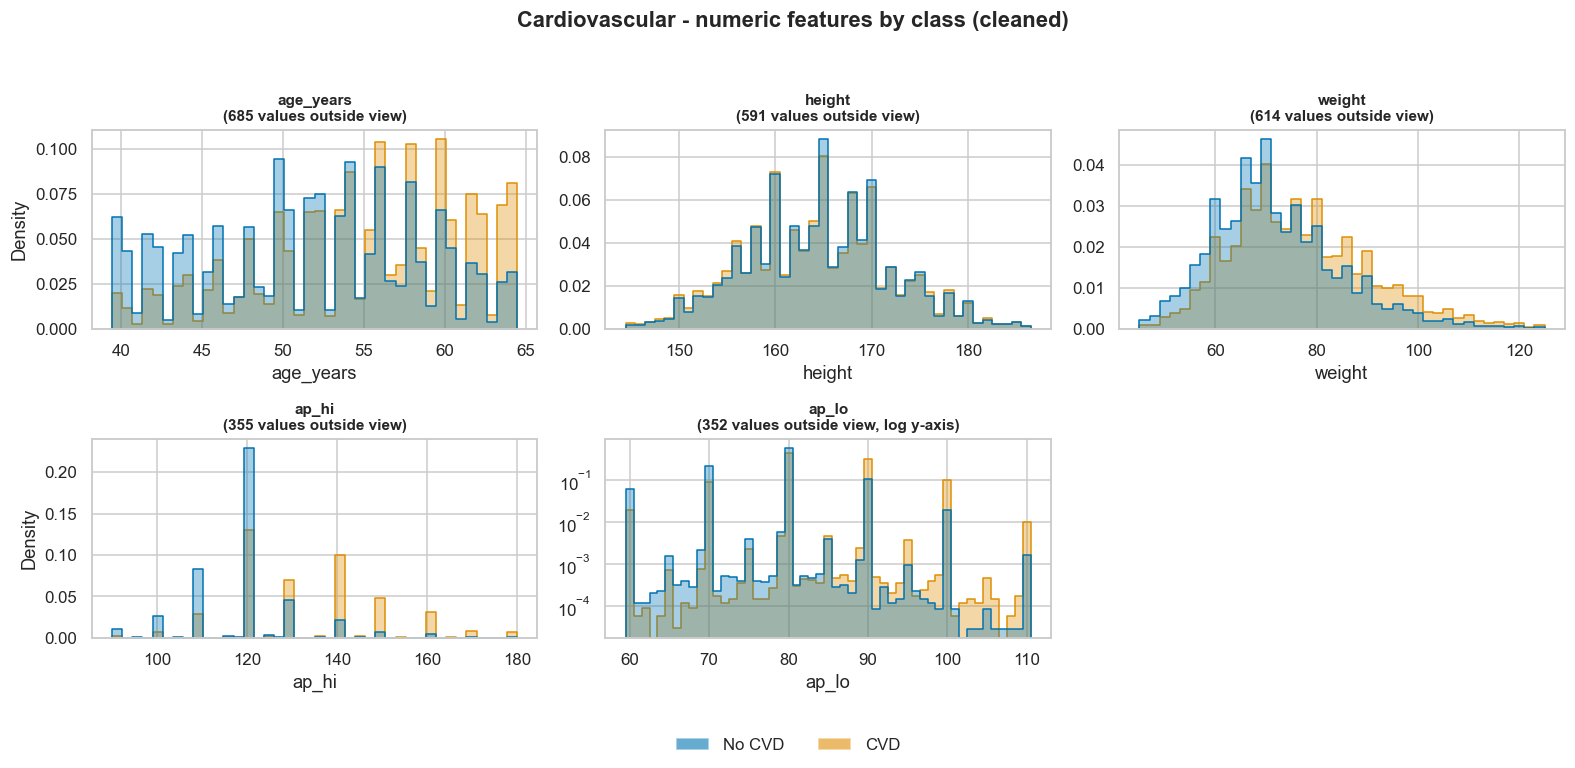

In [11]:
# Execute configured data cleaning pipelines across all raw datasets via dictionary comprehension.
# Stores returned result objects containing the cleaned DataFrame, transformation logs, and residual violations.
cleaning = {name: apply_cleaning(df, DATASETS[name]) for name, df in raw.items()}

# Iterate through cleaning result objects to audit transformation steps, memory impact, and post-clean distributions
for name, result in cleaning.items():
    cfg = DATASETS[name]
    print(f"\n{name.upper()}")

    # Display step-by-step transformation logs (e.g., record drop counts, missing value imps) indexed by step name
    display(result.log.set_index("step").round(4))
    
    # Output any residual validity rule violations remaining after deduplication and cleaning steps
    if not result.rule_violations.empty:
        display(result.rule_violations.rename("rows violating (after de-duplication)").to_frame())

    # Calculate exact memory footprint before and after cleaning (converting bytes to Megabytes via deep introspection)
    raw_mb = raw[name].memory_usage(deep=True).sum() / 1e6
    clean_mb = result.data.memory_usage(deep=True).sum() / 1e6
    print(f"Memory: {raw_mb:.1f} MB -> {clean_mb:.1f} MB")

    # Render and export updated target class distribution plots post-cleaning
    ep.plot_class_distribution(
        result.data[cfg.target], 
        cfg.class_labels,
        f"{name.capitalize()} - class distribution (cleaned)", 
        f"{name}_class_distribution_cleaned.png",
    )
    
    # Render and save class-stratified numeric feature distributions for datasets with configured range constraints
    if cfg.range_rules:
        ep.plot_numeric_by_class(
            result.data, 
            cfg.cleaned_feature_types()["numeric"],  # Dynamically fetch updated numeric feature names post-cleaning
            cfg.target, 
            cfg.class_labels,
            f"{name.capitalize()} - numeric features by class (cleaned)", 
            f"{name}_numeric_by_class_cleaned.png",
        )

## 10 · Feature correlations

Spearman correlations on the **cleaned** features (target excluded). The lower triangle avoids showing every pair twice, and the diverging colormap is centred on zero so sign is readable at a glance.

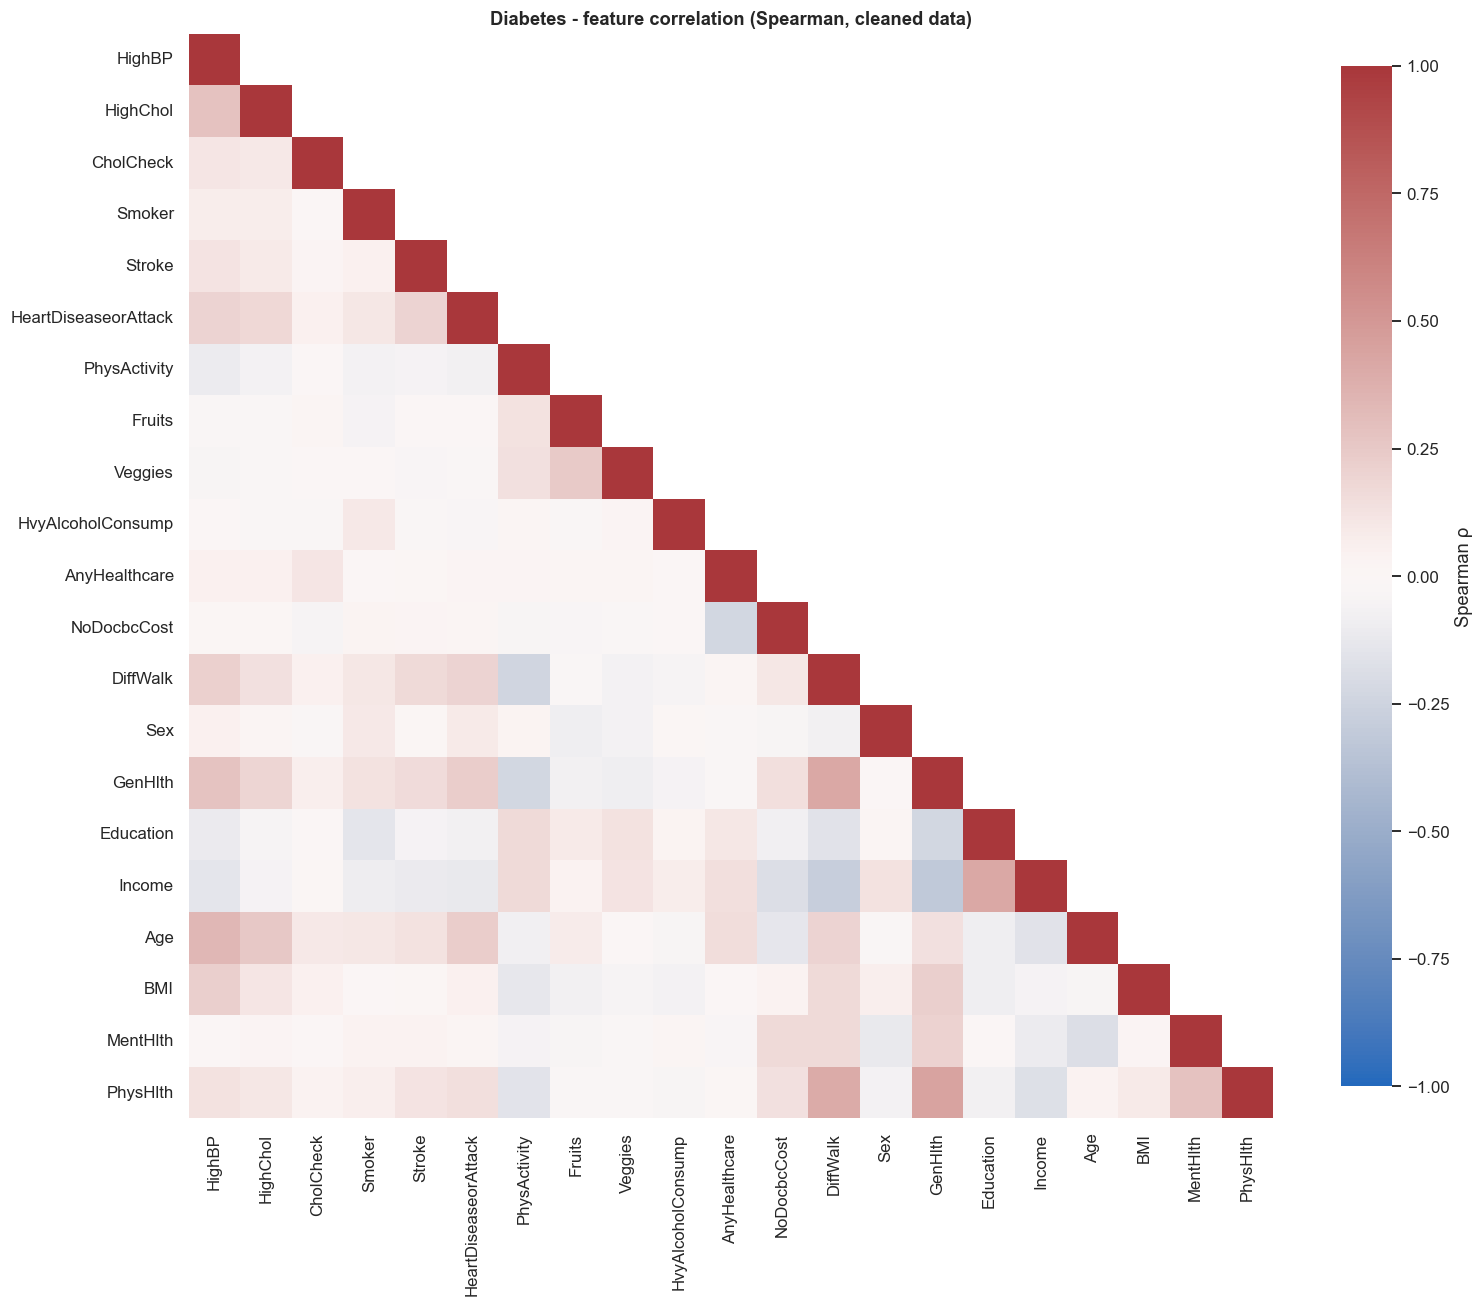

DIABETES - feature pairs with |rho| >= 0.5


'none'

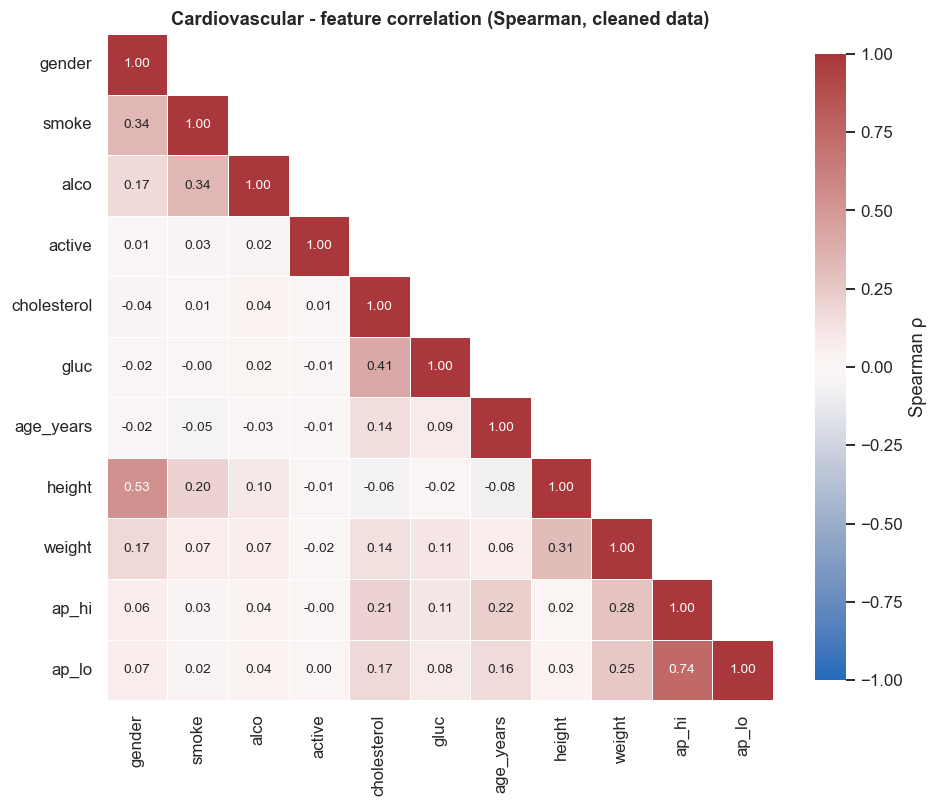

CARDIOVASCULAR - feature pairs with |rho| >= 0.5


,feature_a,feature_b,rho
0,ap_hi,ap_lo,0.743
1,gender,height,0.533


In [12]:
# Iterate through cleaned dataset results to evaluate inter-feature dependencies and identify collinearity
for name, result in cleaning.items():
    cfg = DATASETS[name]
    
    # Flatten the dictionary of cleaned feature categories (numeric, ordinal, binary) 
    # into a single unified list of predictor column names
    features = [col for cols in cfg.cleaned_feature_types().values() for col in cols]
    
    # Compute the non-parametric Spearman rank correlation matrix to measure monotonic inter-feature relationships
    corr = result.data[features].corr(method="spearman")

    # Render and export a correlation matrix heatmap for visual inspection of feature interdependencies
    ep.plot_correlation_heatmap(
        corr, 
        f"{name.capitalize()} - feature correlation (Spearman, cleaned data)",
        f"{name}_feature_correlation.png",
    )
    
    # Extract distinct predictor pairs whose absolute Spearman correlation coefficient (|rho|) equals or exceeds 0.5
    pairs = top_correlated_pairs(corr, threshold=0.5)
    
    print(f"{name.upper()} - feature pairs with |rho| >= 0.5")
    display(pairs.round(3) if not pairs.empty else "none")

In [13]:
# Iterate through loaded datasets to analyze correlation changes in designated ordered feature pairs
for name, df in raw.items():
    cfg = DATASETS[name]
    
    # Skip datasets that do not have an explicitly configured ordered feature pair
    if cfg.ordered_pair is None:
        continue
        
    # Unpack the feature pair names (e.g., hierarchically or sequentially ordered variables)
    higher, lower = cfg.ordered_pair
    
    # Retrieve the post-cleaning DataFrame for comparison against raw data
    cleaned_df = cleaning[name].data
    
    # Construct a comparison matrix computing linear (Pearson) and monotonic (Spearman) 
    # correlation coefficients before and after preprocessing
    comparison = pd.DataFrame(
        {
            "raw": {
                "Pearson": df[higher].corr(df[lower]),
                "Spearman": df[higher].corr(df[lower], method="spearman"),
            },
            "cleaned": {
                "Pearson": cleaned_df[higher].corr(cleaned_df[lower]),
                "Spearman": cleaned_df[higher].corr(cleaned_df[lower], method="spearman"),
            },
        }
    ).round(3)
    
    print(f"{name.upper()}: correlation between {higher} and {lower}")
    display(comparison)

CARDIOVASCULAR: correlation between ap_hi and ap_lo


,raw,cleaned
Pearson,0.016,0.735
Spearman,0.735,0.743


## Findings

In [14]:
# Iterate through all raw datasets to generate an executive diagnostic report summarizing data cleaning outcomes
for name, df in raw.items():
    cfg = DATASETS[name]
    log = cleaning[name].log.set_index("step")
    dup = dup_stats[name]
    assoc = associations[name]
    
    # Extract the top 3 features exhibiting the strongest absolute rank correlation with the target variable
    strongest = assoc.abs().nlargest(3).index

    print(name.upper())
    # Report initial raw dataset sample size and baseline positive class prevalence
    print(f"- Raw size {len(df):,} rows; positive class {df[cfg.target].mean():.1%}.")
    
    # Report total deduplicated rows removed and the resulting shift in class prevalence
    print(f"- Duplicates: {dup['redundant']:,} redundant rows ({dup['pct']:.2f}%) removed; "
          f"positive prevalence {dup['prev_before']:.2%} -> {dup['prev_after']:.2%}.")
    
    # Report label ambiguity (identical feature vectors mapped to conflicting class labels), 
    # which establishes an empirical Bayes accuracy upper bound for deterministic classifiers
    print(f"- Feature vectors with conflicting labels: {dup['conflicting_rows']:,} rows "
          f"({100 * dup['conflicting_rows'] / len(df):.1f}%), an accuracy ceiling for any model.")
    
    # Extract row deletion metrics resulting from domain-specific validity constraint checks
    validity = log.loc["2. apply validity rules"]
    print(f"- Validity rules remove {int(validity['rows_removed']):,} rows ({validity['pct_removed']:.2f}%).")
    
    # Print the top 3 correlated features alongside their signed Spearman rank correlation coefficients
    print("- Strongest raw feature-target associations: "
          + ", ".join(f"{f} ({assoc[f]:+.2f})" for f in strongest) + ".")
    
    # Report final preprocessed dataset sample size and post-cleaning target prevalence from the terminal pipeline step
    print(f"- Final cleaned size: {int(log['rows_after'].iloc[-1]):,} rows; "
          f"positive class {log['target_prevalence'].iloc[-1]:.1%}.\n")

DIABETES
- Raw size 253,680 rows; positive class 13.9%.
- Duplicates: 24,206 redundant rows (9.54%) removed; positive prevalence 13.93% -> 15.29%.
- Feature vectors with conflicting labels: 5,218 rows (2.1%), an accuracy ceiling for any model.
- Validity rules remove 0 rows (0.00%).
- Strongest raw feature-target associations: GenHlth (+0.29), HighBP (+0.26), BMI (+0.23).
- Final cleaned size: 229,474 rows; positive class 15.3%.

CARDIOVASCULAR
- Raw size 70,000 rows; positive class 50.0%.
- Duplicates: 24 redundant rows (0.03%) removed; positive prevalence 49.97% -> 49.98%.
- Feature vectors with conflicting labels: 34 rows (0.0%), an accuracy ceiling for any model.
- Validity rules remove 1,364 rows (1.95%).
- Strongest raw feature-target associations: ap_hi (+0.45), ap_lo (+0.36), age (+0.23).
- Final cleaned size: 68,612 rows; positive class 49.5%.



### Decisions carried into `02_data_preparation.ipynb`

1. Remove exact duplicates on the modelling columns; report the prevalence shift.
2. Apply the validity rules in `data_pipeline.py` (cardiovascular only), including `ap_hi > ap_lo`.
3. Convert `age` from days to years (`age_years`); recode `gender` 1/2 → 0/1.
4. Downcast integer-valued columns (`int8` for binary/ordinal/target, `int16` for numeric).
5. Keep scaling and encoding **out** of preparation: they belong inside a per-training-subset pipeline (fit on the subset only) to avoid leakage.
6. Keep the natural class prevalence in the test set. Training subsets are balanced 50/50, so at a fixed 0.5 threshold accuracy, precision and F1 will be distorted; report PR-AUC against the test prevalence as its chance level.